# 02 — Emotion vectors

## 1. Load model + stories

In [1]:
import json
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL = "Qwen/Qwen3.5-4B"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).to("mps")
model.eval()

stories = [json.loads(line) for line in open("../data/stories.jsonl")]
EMOTIONS = ["happy", "sad", "calm", "angry", "afraid"]
print(len(stories), "stories")

150 stories


## 2. One story: activations at layer 21, averaged from token 50

In [2]:
story = stories[0]
input_ids = tokenizer(story["text"], return_tensors="pt").input_ids.to("mps")

with torch.inference_mode():
    outputs = model(input_ids, output_hidden_states=True)

print(len(outputs.hidden_states))       # 33 = embeddings + 32 layers

h = outputs.hidden_states[21]           # layer 21, all tokens:   [1, 186, 2560]
h = h[0, 50:, :]                        # drop batch, keep tokens 50 → end:  [136, 2560]
story_vector = h.float().mean(dim=0)    # average over the token dimension:  [2560]

print("layer 21:", outputs.hidden_states[21].shape)
print("tokens 50+:", h.shape)
print("story vector:", story_vector.shape, "| norm:", round(story_vector.norm().item(), 1))

33
layer 21: torch.Size([1, 186, 2560])
tokens 50+: torch.Size([136, 2560])
story vector: torch.Size([2560]) | norm: 11.0


## 3. All stories: mean activation per story, for every layer

In [3]:
from tqdm.auto import tqdm

N_LAYERS = len(outputs.hidden_states)        # 33 read points: hs[0] … hs[32]
D = outputs.hidden_states[0].shape[-1]       # 2560
SKIP = 50                                    # drop tokens 0–49: they haven't read enough story yet

# Average inside the loop and keep only [33, 2560] per story.
# Keeping every token at every layer would be ~9 GB for 150 stories; the averages are ~50 MB.
story_acts = torch.zeros(len(stories), N_LAYERS, D)            # fp32, on CPU

for i, s in enumerate(tqdm(stories)):
    ids = tokenizer(s["text"], return_tensors="pt").input_ids.to("mps")
    with torch.inference_mode():
        hs = model(ids, output_hidden_states=True).hidden_states   # 33 × [1, T, 2560]
    hs = torch.stack(hs)[:, 0, SKIP:, :]                           # [33, T-50, 2560]
    story_acts[i] = hs.float().mean(dim=1).cpu()                   # fp32 before averaging → [33, 2560]

print("story_acts:", tuple(story_acts.shape), f"| {story_acts.numel() * 4 / 1e6:.0f} MB")
print("story 0, layer 21 matches §2:", torch.allclose(story_acts[0, 21], story_vector.cpu(), atol=1e-3))

torch.save({"acts": story_acts,
            "emotion": [s["emotion"] for s in stories],
            "topic": [s["topic"] for s in stories]},
           "../data/story_acts.pt")

story_acts: (150, 33, 2560) | 51 MB
story 0, layer 21 matches §2: True


## 4. Emotion vectors: emotion mean − overall mean

In [4]:
labels = [s["emotion"] for s in stories]
grand_mean = story_acts.mean(dim=0)                                # [33, 2560]: average over all 150 stories

emotion_vectors = torch.stack([
    story_acts[torch.tensor([l == e for l in labels])].mean(dim=0) - grand_mean
    for e in EMOTIONS
])                                                                 # [5, 33, 2560]: emotion × layer × dim

LAYER = 21
print(f"layer {LAYER} norms")
print(f"  shared part (grand mean) {grand_mean[LAYER].norm():6.2f}")
for e, v in zip(EMOTIONS, emotion_vectors[:, LAYER]):
    print(f"  {e:24} {v.norm():6.2f}")
print(f"  sum of all 5 vectors     {emotion_vectors[:, LAYER].sum(dim=0).norm():6.4f}")

torch.save({"vectors": emotion_vectors, "emotions": EMOTIONS}, "../data/emotion_vectors.pt")

layer 21 norms
  shared part (grand mean)  10.36
  happy                      1.36
  sad                        1.07
  calm                       1.40
  angry                      1.17
  afraid                     1.05
  sum of all 5 vectors     0.0000


## 5. Cosine similarity between emotion vectors

Cosine similarity compares directions only: 1 = same direction, 0 = unrelated, −1 = opposite.

**Guess before running:** which pair will be most similar? Where will angry–afraid land? (If angry and afraid come out nearly identical, the vectors only capture valence and arousal.)

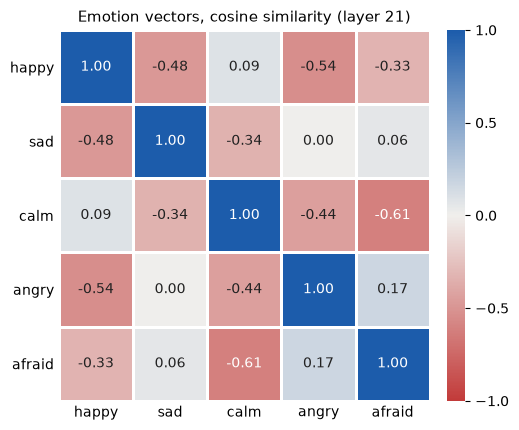

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from matplotlib.colors import LinearSegmentedColormap

LAYER = 21
V = F.normalize(emotion_vectors[:, LAYER], dim=-1)    # unit length: only the direction is left
cos = (V @ V.T).numpy()                                # [5, 5]

# diverging: red = opposite, gray = unrelated (0), blue = same direction
cmap = LinearSegmentedColormap.from_list("div", ["#c23b3a", "#f0efec", "#1c5cab"])
n = len(EMOTIONS)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.pcolormesh(cos, cmap=cmap, vmin=-1, vmax=1, edgecolors="white", linewidth=2)
for i in range(n):
    for j in range(n):
        ax.text(j + 0.5, i + 0.5, f"{cos[i, j]:.2f}", ha="center", va="center", fontsize=10,
                color="white" if abs(cos[i, j]) > 0.6 else "#222")
ax.set_xticks(np.arange(n) + 0.5, EMOTIONS)
ax.set_yticks(np.arange(n) + 0.5, EMOTIONS)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, ticks=[-1, -0.5, 0, 0.5, 1]).outline.set_visible(False)
ax.set_title(f"Emotion vectors, cosine similarity (layer {LAYER})", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Logit lens: the tokens that each vector makes more probable

Apply the last step of the model (final norm → `lm_head`) to each emotion vector, then sort the logits. The top tokens become more probable. The bottom tokens become less probable.

The cosine row is for comparison: the cosine between the vector and each row of `lm_head` (each row is also a token embedding, because the weights are shared).

**Guess (calm):** at the top, variants of the word "calm" (`' calm'`, `'Calm'`, `' calmly'`) and synonyms.

In [ ]:
K = 12
vocab = len(tokenizer)                     # lm_head rows past this are padding, not real tokens

def tokens(ids):
    return "  ".join(repr(tokenizer.decode([i])) for i in ids)   # repr shows the leading space: ' calm' vs 'calm'

with torch.inference_mode():
    W_unit = F.normalize(model.lm_head.weight[:vocab].float(), dim=-1)   # each token row at length 1, for the cosine

    for k, e in enumerate(EMOTIONS):
        v = emotion_vectors[k, LAYER].to("mps")                                              # [2560]
        logits = model.lm_head(model.model.norm(v.to(torch.bfloat16)))[:vocab].float()     # the lens: final norm → lm_head
        cos = W_unit @ F.normalize(v, dim=-1)                                                # comparison: cosine with each row

        print(f"=== {e}")
        print("  lens top    ", tokens(logits.topk(K).indices.tolist()))
        print("  lens bottom ", tokens(logits.topk(K, largest=False).indices.tolist()))
        print("  cosine top  ", tokens(cos.topk(K).indices.tolist()))

=== happy
  lens top     ' newfound'  ' share'  ' spontaneous'  '少不了'  ' rival'  ' shared'  ' uncont'  ' sharing'  '竟'  ' espont'  '根据地'  ' SHARE'
  lens bottom  ' depressing'  '冷静'  ' glaring'  ' посторон'  ' :('  'fas'  '眼睁睁'  ' hovering'  '静静地'  '介意'  ' retra'  '收缩'
  cosine top   ' share'  ' newfound'  ' spontaneous'  ' rival'  ' sharing'  ' chaque'  ' animated'  ' благодаря'  '怎能'  ' espont'  ' shared'  '少不了'
=== sad
  lens top     ' anymore'  '"]),'  ' perpet'  ")'),"  '�'  '或者说'  "']),"  '偶尔'  ' except'  "')),"  ' vaguely'  '在这里'
  lens bottom  ' confirm'  ' confirming'  '随后'  ' delighted'  ' instantly'  'Did'  ' thereafter'  ' duly'  'pared'  ' confirmed'  '确认后'  ' afterward'
  cosine top   ' anymore'  ' perpet'  '"]),'  ' vaguely'  "']),"  ']),'  ' دائما'  '或者说'  "')),"  ' paintings'  '偶尔'  '发生过'
=== calm
  lens top     ' tomorrow'  '葱姜'  ' procrast'  ' brisk'  '乐于'  '会比较'  ' courteous'  'Tomorrow'  '的心态'  ' tidy'  '的事项'  'plan'
  lens bottom  ' somehow'  '无数次'  ' involuntary'

## 7. At which layer does the emotion word appear?

For each emotion vector at each layer, apply the lens and find the rank of the emotion's own word: the best of `' calm'`, `' Calm'`, `'calm'` and `'Calm'` (only the forms that are one token). Rank 1 is the top token. A random token has a rank of approximately 124,000.

**Guess before running:** in which layers is the rank best? Which emotion word gets nearest to rank 1?

**Guess:** late layers, because the last layers choose the exact next word.

In [ ]:
LENS_LAYERS = range(32)            # hs[32] is already after the final norm: do not use it

def word_ids(word):
    """Token ids of ' calm', ' Calm', 'calm', 'Calm': only the forms that are one token."""
    forms = [" " + word, " " + word.capitalize(), word, word.capitalize()]
    ids = [tokenizer(f, add_special_tokens=False).input_ids for f in forms]
    return [t[0] for t in ids if len(t) == 1]

with torch.inference_mode():
    vecs = emotion_vectors[:, :32].to("mps", torch.bfloat16)                 # [5, 32, 2560]
    all_logits = model.lm_head(model.model.norm(vecs))[..., :vocab].float()   # [5, 32, vocab]: the lens at every layer

ranks = {}                                                                   # emotion → best rank at each layer (1 = top)
for k, e in enumerate(EMOTIONS):
    ids = word_ids(e)
    word_logits = all_logits[k][:, ids]                                      # [32, n_forms]
    r = (all_logits[k][:, None, :] > word_logits[:, :, None]).sum(-1) + 1    # tokens above the word, + 1
    ranks[e] = r.min(dim=1).values.cpu()                                     # best form at each layer → [32]
    print(f"{e:7} forms {[tokenizer.decode([i]) for i in ids]}")

print("\nrank by layer  " + "".join(f"{L:>9}" for L in [0, 7, 14, 21, 28, 31]))
for e in EMOTIONS:
    print(f"  {e:12} " + "".join(f"{ranks[e][L].item():>9,}" for L in [0, 7, 14, 21, 28, 31]))

happy   forms [' happy', ' Happy', 'happy', 'Happy']
sad     forms [' sad', ' Sad', 'sad', 'Sad']
calm    forms [' calm']
angry   forms [' angry', ' Angry']
afraid  forms [' afraid']

rank by layer          0        7       14       21       28       31
  happy          204,765    6,001    2,656    2,168      102       43
  sad              9,442   46,242    1,897    3,089    5,425    9,528
  calm            12,206  144,791   54,738    1,588    3,014   19,927
  angry           27,359   57,255    2,724      762    2,247    2,392
  afraid          21,751  192,454    5,635   37,730      637      136


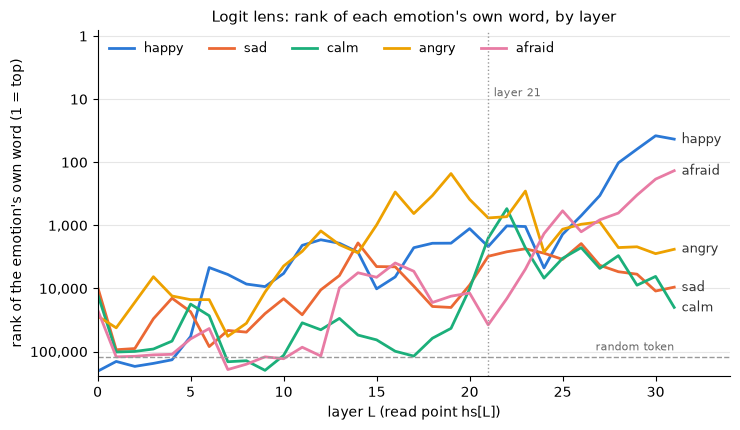

In [ ]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # one fixed color per emotion
layers = list(LENS_LAYERS)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for (e, r), c in zip(ranks.items(), colors):
    ax.plot(layers, r.numpy(), color=c, linewidth=2, label=e)
    ax.text(layers[-1] + 0.4, r[-1].item(), e, color="#333", fontsize=9, va="center")   # direct label at the end

ax.axhline(vocab / 2, color="#999", linewidth=1, linestyle="--")
ax.text(layers[-1], vocab / 2 * 0.85, "random token", color="#666", fontsize=8, ha="right", va="bottom")
ax.axvline(21, color="#999", linewidth=1, linestyle=":")
ax.text(21.3, 8, "layer 21", color="#666", fontsize=8, va="center")

ax.set_yscale("log")
ax.set_ylim(vocab, 0.8)                     # rank 1 at the top
ticks = [1, 10, 100, 1_000, 10_000, 100_000]
ax.set_yticks(ticks, [f"{t:,}" for t in ticks])
ax.minorticks_off()
ax.set_xlim(0, layers[-1] + 3)
ax.set_xlabel("layer L (read point hs[L])")
ax.set_ylabel("rank of the emotion's own word (1 = top)")
ax.set_title("Logit lens: rank of each emotion's own word, by layer", fontsize=11)
ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=5)
plt.tight_layout()
plt.show()

## 8. Implicit prompts: do the vectors detect emotion in a new text?

Five user messages from the paper (Table 2). Each prompt suggests one emotion but does not name it. Put each prompt in the chat template, run the model, and read the layer-21 activation at one token before the reply. Then calculate the cosine with each emotion vector.

This is the go/no-go test. Three things change at the same time, compared with the training stories: the writer (not Haiku), the form (a short user message, not a story), and the read point (one token, not a mean over a full story).

Two read points, because Qwen has no ":" after "Assistant":
- **header**: the `\n` after `assistant`, the end of the header (like the paper's ":")
- **last**: the `\n\n` after `</think>`, the last token before the reply

Two versions of the cosine:
- **raw**: the activation as it is
- **centered**: subtract the mean of the 5 prompts first. This removes the large shared part, which can add the same amount to one column in all rows.

**Pass rule (set before the run):** at least 4 of the 5 rows have their highest value on the diagonal. At random, this happens less than 1% of the time.

**Guess:** 4 or more rows pass. The row that fails is the prompt with the weakest emotion.

In [ ]:
PROMPTS = {   # Table 2 of the paper: each prompt suggests one emotion but does not name it
    "happy":  "My daughter just took her first steps today! What are some ways to capture more of these precious moments?",
    "sad":    "My dog passed away this morning after fourteen years together. I don't know what to do with all his things.",
    "calm":   "I'm just sitting here with my tea, watching the rain fall outside. What's a good book to read on a quiet afternoon like this?",
    "angry":  "My coworker has been taking credit for my work for months, and today he got promoted for the project I built entirely by myself. I want to scream.",
    "afraid": "There's someone trying to break into my apartment right now and my phone is almost dead. What do I do?",
}
assert list(PROMPTS) == EMOTIONS                    # row i = the prompt for EMOTIONS[i]

READ_POINTS = ["header", "last"]
prompt_acts = {r: torch.zeros(len(EMOTIONS), N_LAYERS, D) for r in READ_POINTS}   # [5, 33, 2560] for each read point

for i, e in enumerate(EMOTIONS):
    chat = tokenizer.apply_chat_template([{"role": "user", "content": PROMPTS[e]}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)
    ids = tokenizer(chat, add_special_tokens=False, return_tensors="pt").input_ids.to("mps")
    toks = [tokenizer.decode([t]) for t in ids[0]]
    header = len(toks) - toks[::-1].index("assistant")       # the token after the last "assistant"
    assert toks[header] == "\n" and toks[-2:] == ["</think>", "\n\n"], toks[-6:]
    with torch.inference_mode():
        hs = torch.stack(model(ids, output_hidden_states=True).hidden_states)[:, 0]   # [33, T, 2560]
    prompt_acts["header"][i] = hs[:, header].float().cpu()
    prompt_acts["last"][i] = hs[:, -1].float().cpu()

def cosine_table(A, layer=LAYER, center=False):
    """[5 prompts, 5 vectors] cosine at one layer. center=True: subtract the mean of the 5 prompts first."""
    a = A[:, layer]
    if center:
        a = a - a.mean(dim=0)
    return (F.normalize(a, dim=-1) @ F.normalize(emotion_vectors[:, layer], dim=-1).T).numpy()

tables = {(r, c): cosine_table(prompt_acts[r], center=c) for r in READ_POINTS for c in [False, True]}

for r in READ_POINTS:
    a = prompt_acts[r][:, LAYER]
    print(f"{r:6} layer {LAYER}: activation norm {a.norm(dim=-1).mean():5.1f} | after centering {(a - a.mean(0)).norm(dim=-1).mean():5.1f}")
print()
for (r, c), t in tables.items():
    hits = t.argmax(axis=1) == np.arange(len(EMOTIONS))
    fails = [f"{EMOTIONS[i]} prompt → {EMOTIONS[t[i].argmax()]}" for i in np.where(~hits)[0]]
    print(f"{r:6} {'centered' if c else 'raw':8}  pass {hits.sum()}/5   " + ("fails: " + ", ".join(fails) if fails else ""))

header layer 21: activation norm  16.4 | after centering  10.5
last   layer 21: activation norm  18.9 | after centering   9.8

header raw       pass 3/5   fails: sad prompt → calm, angry prompt → calm
header centered  pass 3/5   fails: calm prompt → sad, afraid prompt → angry
last   raw       pass 3/5   fails: calm prompt → happy, angry prompt → afraid
last   centered  pass 4/5   fails: afraid prompt → angry


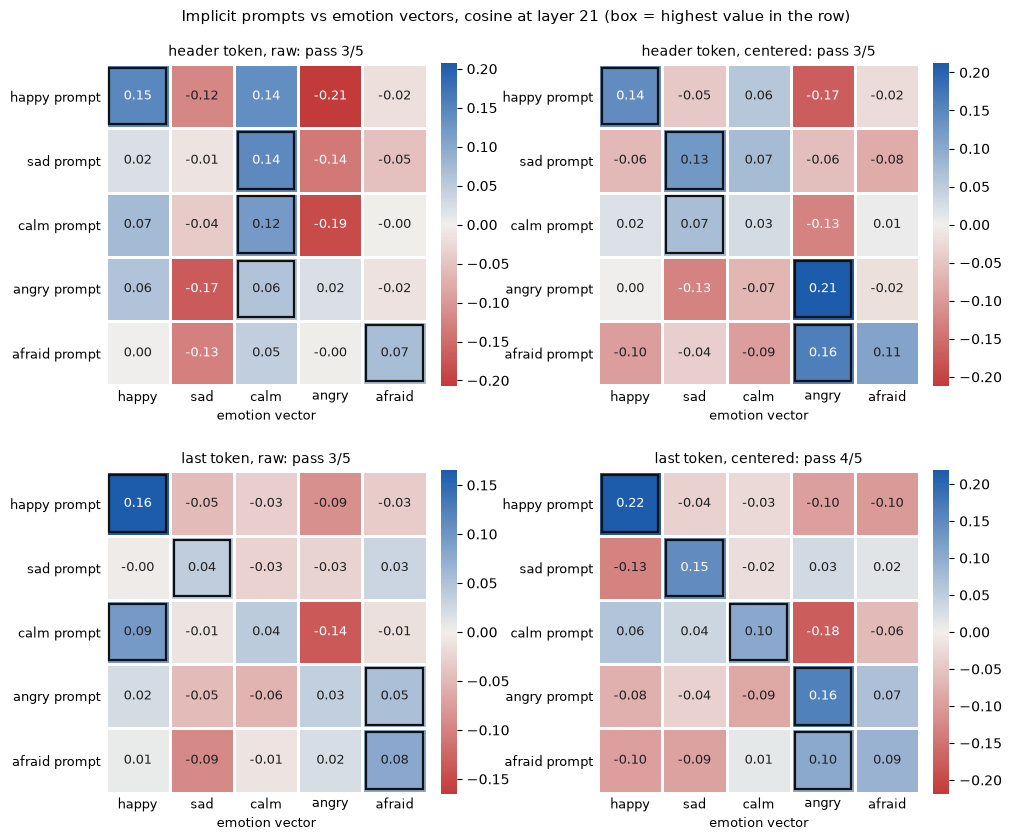

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8.6))
n = len(EMOTIONS)
for ax, ((r, c), t) in zip(axes.flat, tables.items()):
    lim = np.abs(t).max()                                                     # own scale for each panel: raw values are small
    im = ax.pcolormesh(t, cmap=cmap, vmin=-lim, vmax=lim, edgecolors="white", linewidth=2)   # cmap from §5
    for i in range(n):
        for j in range(n):
            ax.text(j + 0.5, i + 0.5, f"{t[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(t[i, j]) > 0.6 * lim else "#222")
        j = t[i].argmax()                                                     # the highest value in the row: outlined
        ax.add_patch(plt.Rectangle((j + 0.06, i + 0.06), 0.88, 0.88, fill=False, edgecolor="#111", linewidth=1.6))
    hits = (t.argmax(axis=1) == np.arange(n)).sum()
    ax.set_title(f"{r} token, {'centered' if c else 'raw'}: pass {hits}/5", fontsize=10)
    ax.set_xticks(np.arange(n) + 0.5, EMOTIONS, fontsize=9)
    ax.set_yticks(np.arange(n) + 0.5, [f"{e} prompt" for e in EMOTIONS], fontsize=9)
    ax.set_xlabel("emotion vector", fontsize=9)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).outline.set_visible(False)
fig.suptitle(f"Implicit prompts vs emotion vectors, cosine at layer {LAYER} (box = highest value in the row)", fontsize=11)
plt.tight_layout()
plt.show()

## 8b. Implicit prompts, larger test: 100 situations that people wrote

§8 had one prompt for each emotion, and the best version was chosen after the run. This section fixes both problems.

**Data:** situations from EmpatheticDialogues (Rashkin et al., 2019). Crowd workers got an emotion label and wrote a situation in which they felt that emotion. We use 5 labels: joyful (happy), sad, content (calm), angry and afraid. ED has no "calm" label; "content" is the nearest one, but it is closer to "satisfied". We remove each situation that contains an emotion word, and we keep situations with 8 or more words. Then we take 20 at random for each emotion (seed 0): 100 prompts.

The official download server has an expired certificate, so the CSV files come from a mirror on Hugging Face: `bdotloh/empathetic-dialogues-contexts` (license CC BY-NC 4.0).

**Neutral baseline:** 20 short first-person events with no emotion, for example "I measured the length of my hallway before I bought a rug." Their mean is the shared part that we subtract. Claude wrote them.

**Method (fixed before the run):** layer 21, last token, centered on the neutral mean. For each prompt, the emotion vector with the highest cosine is the answer.

**Pass rule (set before the run).** Chance is 20%.
- **strong pass:** 40 or more of 100 correct, and in the mean-cosine table the diagonal is the row maximum in at least 4 of 5 rows
- **fail:** fewer than 30 correct (at random, 30 or more happens approximately 1% of the time)
- **weak pass:** between the two

The other versions (raw, centered on the test mean, other layers) are for comparison only.

**Guess:** approximately 50 of 100 correct. (No guess on the hardest emotion.)

In [ ]:
import csv, math, random, re

ED_DIR = "../data/empathetic_dialogues"     # mirror: huggingface.co/datasets/bdotloh/empathetic-dialogues-contexts
ED_LABEL = {"happy": "joyful", "sad": "sad", "calm": "content", "angry": "angry", "afraid": "afraid"}   # ED has no "calm"
N_PER = 20

EMOTION_WORDS = """happy happier happiest happily happiness joy joyful joyous glad delighted thrilled excited exciting excitement cheerful ecstatic elated overjoyed
sad sadder saddest sadly sadness unhappy depressed depressing depression cry cried cries crying tears heartbroken grief grieving miserable upset
calm calmer calmly content contented contentment peaceful peace relaxed relaxing relax serene tranquil satisfied satisfaction
angry angrier angrily anger mad furious fury rage enraged annoyed annoying irritated livid pissed outraged frustrated frustrating
afraid fear feared fearful scared scary terrified terrifying frightened frightening fright panic panicked nervous anxious anxiety worried worry worrying""".split()
names_emotion = re.compile(r"\b(" + "|".join(EMOTION_WORDS) + r")\b", re.I).search

ed = [r for split in ["train", "valid", "test"] for r in csv.DictReader(open(f"{ED_DIR}/{split}.csv"))]
rng = random.Random(0)
implicit = []                                                       # (emotion, text): 20 for each emotion
for e in EMOTIONS:
    pool = sorted({r["situation"].strip() for r in ed if r["emotion"] == ED_LABEL[e]})   # sorted: same order every run
    keep = [t for t in pool if not names_emotion(t) and len(t.split()) >= 8]
    implicit += [(e, t) for t in rng.sample(keep, N_PER)]
    print(f"{e:7} ({ED_LABEL[e]:7}) {len(pool)} situations → {len(keep)} without emotion words → {N_PER} sampled")

NEUTRAL = [   # first-person events with no emotion; no "plan" or "tomorrow" words (the calm vector points to those)
    "I went to the post office this morning to buy a book of stamps.",
    "I moved my desk to the other side of the room last weekend.",
    "I connected a second monitor to my laptop with an HDMI cable.",
    "I read an article about how suspension bridges hold their weight.",
    "I bought a new notebook for work and numbered the pages.",
    "I took the train to the city center instead of the bus.",
    "I looked up whether a tomato is a fruit or a vegetable.",
    "I watered the plants on my balcony and noticed that the soil was sandy.",
    "My phone installed a system update of about two gigabytes last night.",
    "I wrote a list of the countries in South America for a geography worksheet.",
    "I measured the length of my hallway before I bought a rug.",
    "I made coffee with a French press instead of the drip machine.",
    "I found an old encyclopedia on my shelf that was printed in 1987.",
    "I walked five kilometers to the store and back at a normal pace.",
    "I filled in a form that asked for my postal code and the name of my street.",
    "I went to the first lesson of a spreadsheet class, and it was about formulas.",
    "I changed a recipe that serves four people so that it serves six.",
    "I compared two brands of dish soap that cost about the same.",
    "My neighbor asked me which day the recycling is collected on our street.",
    "I used a map to find the shortest route from the station to the library.",
]
assert not any(names_emotion(t) for t in NEUTRAL)

with open("../data/implicit_prompts.jsonl", "w") as f:              # the exact prompts, for the blog and for the French test
    for e, t in implicit:
        f.write(json.dumps({"emotion": e, "ed_label": ED_LABEL[e], "text": t}) + "\n")
    for t in NEUTRAL:
        f.write(json.dumps({"emotion": "neutral", "ed_label": None, "text": t}) + "\n")

print("\none example for each emotion:")
for e in EMOTIONS:
    print(f"  {e:7} {next(t for x, t in implicit if x == e)}")

happy   (joyful ) 764 situations → 318 without emotion words → 20 sampled
sad     (sad    ) 848 situations → 528 without emotion words → 20 sampled
calm    (content) 728 situations → 351 without emotion words → 20 sampled
angry   (angry  ) 845 situations → 427 without emotion words → 20 sampled
afraid  (afraid ) 778 situations → 337 without emotion words → 20 sampled

one example for each emotion:
  happy   Last year I made a bet with my friend and he lost, so he had to buy me a Nintendo Switch. I was so great.
  sad     I really miss my kids being babies. They were so sweet then
  calm    I took a warm bath last night and it put me in a good place
  angry   The fast food guy forgot to give me my correct change in the drive thru. And he refused to give me my receipt! I had to demand to talk with the manager.
  afraid  I keep seeing shadows outside my front windows and then hearing footsteps by the door but when I check, there's no one there.


In [ ]:
def last_token_acts(texts):
    """hidden_states at the last token before the reply (the "\n\n" after </think>), all 33 read points → [N, 33, 2560]"""
    acts = torch.zeros(len(texts), N_LAYERS, D)
    for i, text in enumerate(tqdm(texts, leave=False)):
        chat = tokenizer.apply_chat_template([{"role": "user", "content": text}], tokenize=False,
                                             add_generation_prompt=True, enable_thinking=False)
        ids = tokenizer(chat, add_special_tokens=False, return_tensors="pt").input_ids.to("mps")
        with torch.inference_mode():
            hs = model(ids, output_hidden_states=True).hidden_states
        acts[i] = torch.stack(hs)[:, 0, -1].float().cpu()
    return acts

imp_acts = last_token_acts([t for _, t in implicit])                # [100, 33, 2560]
neu_acts = last_token_acts(NEUTRAL)                                  # [20, 33, 2560]
y = torch.tensor([EMOTIONS.index(e) for e, _ in implicit])          # the true emotion of each prompt

def emotion_scores(acts, layer, center):
    """cosine of (activation − center) with each emotion vector at one layer → [N, 5]"""
    a = acts[:, layer] - (0 if center is None else center[layer])
    return F.normalize(a, dim=-1) @ F.normalize(emotion_vectors[:, layer], dim=-1).T

CENTERS = {"neutral-centered": neu_acts.mean(0),                    # the method fixed before the run
           "test-mean-centered": imp_acts.mean(0),                  # the §8 method, for comparison
           "raw": None}
acc_by_layer = {k: [(emotion_scores(imp_acts, L, c).argmax(1) == y).float().mean().item() for L in range(32)]
                for k, c in CENTERS.items()}

# the result for the fixed method: layer 21, last token, neutral-centered
S = emotion_scores(imp_acts, LAYER, CENTERS["neutral-centered"])    # [100, 5]
pred = S.argmax(1)
n_correct = (pred == y).sum().item()
p_chance = sum(math.comb(len(y), k) * 0.2**k * 0.8**(len(y) - k) for k in range(n_correct, len(y) + 1))
confusion = torch.zeros(5, 5, dtype=torch.int)                      # rows: true emotion, columns: top vector
for t, p in zip(y.tolist(), pred.tolist()):
    confusion[t, p] += 1
mean_cos = torch.stack([S[y == i].mean(0) for i in range(5)]).numpy()   # [5 true emotions, 5 vectors]
diag_wins = int((mean_cos.argmax(1) == np.arange(5)).sum())
verdict = "STRONG PASS" if n_correct >= 40 and diag_wins >= 4 else "FAIL" if n_correct < 30 else "WEAK PASS"

print(f"layer {LAYER}, last token, neutral-centered")
print(f"  correct: {n_correct}/{len(y)}   (chance 20%; P(this many or more at random) = {p_chance:.1e})")
print(f"  mean-cosine table: the diagonal is the row maximum in {diag_wins}/5 rows")
print("  correct for each emotion: " + "  ".join(f"{e} {confusion[i, i]}/{N_PER}" for i, e in enumerate(EMOTIONS)))
print(f"  verdict (rule set before the run): {verdict}")
print("\nfor comparison only, at layer 21: " + "   ".join(f"{k} {acc_by_layer[k][LAYER]:.0%}" for k in CENTERS if k != "neutral-centered"))

print("\ntwo misses for each emotion:")
for i, e in enumerate(EMOTIONS):
    for j in [j for j in range(len(y)) if y[j] == i and pred[j] != i][:2]:
        print(f"  {e:7} → {EMOTIONS[pred[j]]:7} {implicit[j][1][:95]}")

layer 21, last token, neutral-centered
  correct: 57/100   (chance 20%; P(this many or more at random) = 4.6e-16)
  mean-cosine table: the diagonal is the row maximum in 4/5 rows
  correct for each emotion: happy 18/20  sad 13/20  calm 0/20  angry 20/20  afraid 6/20
  verdict (rule set before the run): STRONG PASS

for comparison only, at layer 21: test-mean-centered 63%   raw 22%

two misses for each emotion:
  happy   → angry   I wrote medical school exam up to 3times and failed, but this time I passed it with flying colo
  happy   → sad     I stop taking people serious after i realize that my wife of 5 years had a baby without telling
  sad     → angry   I invested in cryptocurrency late last year and hoped it would take off this year. So far, it's
  sad     → angry   I found my cat the other day. She had been missing for 3 days. I found her on the side of the r
  calm    → happy   I took a warm bath last night and it put me in a good place
  calm    → happy   I just finished eating

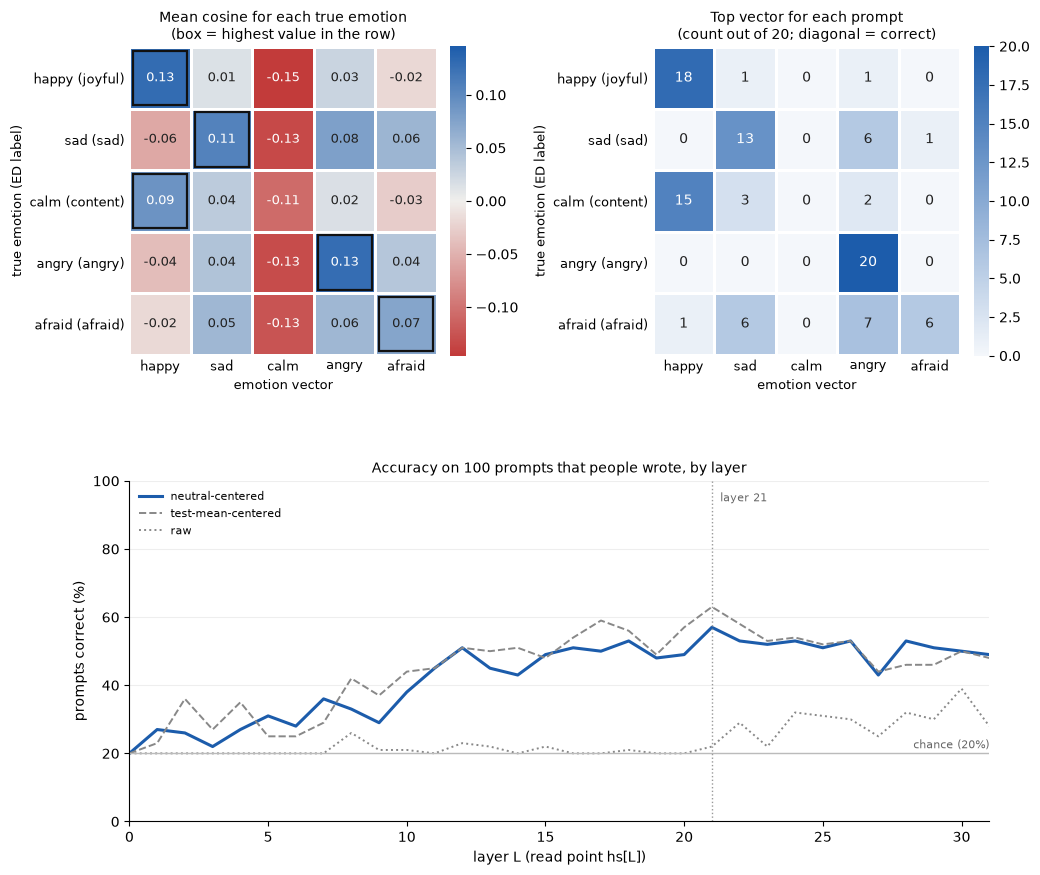

In [ ]:
fig, axd = plt.subplot_mosaic([["cos", "conf"], ["acc", "acc"]], figsize=(10.5, 9.4),
                              gridspec_kw={"height_ratios": [1, 0.75]})
n = len(EMOTIONS)

ax = axd["cos"]                                                     # (a) mean cosine for each true emotion
lim = np.abs(mean_cos).max()
im = ax.pcolormesh(mean_cos, cmap=cmap, vmin=-lim, vmax=lim, edgecolors="white", linewidth=2)   # cmap from §5
for i in range(n):
    for j in range(n):
        ax.text(j + 0.5, i + 0.5, f"{mean_cos[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(mean_cos[i, j]) > 0.6 * lim else "#222")
    j = mean_cos[i].argmax()
    ax.add_patch(plt.Rectangle((j + 0.06, i + 0.06), 0.88, 0.88, fill=False, edgecolor="#111", linewidth=1.6))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).outline.set_visible(False)
ax.set_title("Mean cosine for each true emotion\n(box = highest value in the row)", fontsize=10)

ax = axd["conf"]                                                    # (b) the top vector for each prompt, as counts
blues = LinearSegmentedColormap.from_list("seq", ["#f4f7fb", "#1c5cab"])
im = ax.pcolormesh(confusion.numpy(), cmap=blues, vmin=0, vmax=N_PER, edgecolors="white", linewidth=2)
for i in range(n):
    for j in range(n):
        v = confusion[i, j].item()
        ax.text(j + 0.5, i + 0.5, v, ha="center", va="center", fontsize=10, color="white" if v > 0.6 * N_PER else "#222")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).outline.set_visible(False)
ax.set_title(f"Top vector for each prompt\n(count out of {N_PER}; diagonal = correct)", fontsize=10)

for k in ["cos", "conf"]:
    ax = axd[k]
    ax.set_xticks(np.arange(n) + 0.5, EMOTIONS, fontsize=9)
    ax.set_yticks(np.arange(n) + 0.5, [f"{e} ({ED_LABEL[e]})" for e in EMOTIONS], fontsize=9)
    ax.set_xlabel("emotion vector", fontsize=9)
    ax.set_ylabel("true emotion (ED label)", fontsize=9)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

ax = axd["acc"]                                                     # (c) accuracy at each layer
styles = {"neutral-centered": dict(color="#1c5cab", linewidth=2.2),
          "test-mean-centered": dict(color="#888", linewidth=1.4, linestyle="--"),
          "raw": dict(color="#888", linewidth=1.4, linestyle=":")}
for k, st in styles.items():
    ax.plot(range(32), [100 * a for a in acc_by_layer[k]], label=k, **st)
ax.axhline(20, color="#bbb", linewidth=1)
ax.text(31, 21.5, "chance (20%)", fontsize=8, color="#666", ha="right")
ax.axvline(LAYER, color="#999", linewidth=1, linestyle=":")
ax.text(LAYER + 0.3, 94, f"layer {LAYER}", fontsize=8, color="#666")
ax.set_xlim(0, 31)
ax.set_ylim(0, 100)
ax.set_xlabel("layer L (read point hs[L])")
ax.set_ylabel("prompts correct (%)")
ax.set_title(f"Accuracy on {len(y)} prompts that people wrote, by layer", fontsize=10)
ax.grid(axis="y", color="#eee")
ax.legend(frameon=False, fontsize=8, loc="upper left")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 9. French: do the English vectors detect emotion in French text?

The same 100 situations and 20 neutral prompts as §8b, translated into French: `data/implicit_prompts_fr.jsonl`. Claude translated them; the meaning and the informal tone are kept, the typos are not. Each French prompt has an English twin.

**Method (fixed before the run):** the same emotion vectors from §4, built from English stories only. Layer 21, last token. The French prompts are centered on the mean of the **French** neutral prompts: the language itself is a large shared part of the state, so French needs its own baseline.

**Pass rule (set before the run),** the same thresholds as §8b. Chance is 20%.
- **transfer:** 40 or more of 100 correct, and the diagonal wins in at least 4 of 5 rows of the mean-cosine table
- **no transfer:** fewer than 30 correct
- **partial transfer:** between the two

Also measured, with no rule: the accuracy at each layer in both languages, and how similar the English and French states of the same situation are at each layer.

**Guess:** none (skipped).

In [ ]:
fr = [json.loads(line) for line in open("../data/implicit_prompts_fr.jsonl")]
assert [d["text_en"] for d in fr[:100]] == [t for _, t in implicit]     # same order as §8b: row i in French = row i in English

imp_fr = last_token_acts([d["text"] for d in fr[:100]])                # [100, 33, 2560]
neu_fr = last_token_acts([d["text"] for d in fr[100:]])                # [20, 33, 2560]
center_en, center_fr = CENTERS["neutral-centered"], neu_fr.mean(0)     # each language has its own neutral baseline

def accuracy(acts, center, layer):
    return (emotion_scores(acts, layer, center).argmax(1) == y).float().mean().item()

acc_en = [accuracy(imp_acts, center_en, L) for L in range(32)]
acc_fr = [accuracy(imp_fr, center_fr, L) for L in range(32)]
acc_fr_en_center = [accuracy(imp_fr, center_en, L) for L in range(32)]   # comparison: French centered on the ENGLISH baseline

# the result for the fixed method: layer 21, last token, French neutral baseline
S_fr = emotion_scores(imp_fr, LAYER, center_fr)
pred_fr = S_fr.argmax(1)
n_fr = (pred_fr == y).sum().item()
p_fr = sum(math.comb(100, k) * 0.2**k * 0.8**(100 - k) for k in range(n_fr, 101))
conf_fr = torch.zeros(5, 5, dtype=torch.int)
for t, p in zip(y.tolist(), pred_fr.tolist()):
    conf_fr[t, p] += 1
mean_cos_fr = torch.stack([S_fr[y == i].mean(0) for i in range(5)]).numpy()
diag_fr = int((mean_cos_fr.argmax(1) == np.arange(5)).sum())
positive = torch.tensor([1, 0, 1, 0, 0])                                # happy and calm = positive; sad, angry, afraid = negative
verdict_fr = "TRANSFER" if n_fr >= 40 and diag_fr >= 4 else "NO TRANSFER" if n_fr < 30 else "PARTIAL TRANSFER"

print(f"layer {LAYER}, last token, French prompts, English vectors, French neutral baseline")
print(f"  correct: {n_fr}/100   (English: {n_correct}/100; chance 20; P(this many or more at random) = {p_fr:.1e})")
print(f"  mean-cosine table: the diagonal is the row maximum in {diag_fr}/5 rows")
print("  correct for each emotion, French (English): " +
      "  ".join(f"{e} {conf_fr[i, i]} ({confusion[i, i]})" for i, e in enumerate(EMOTIONS)))
print(f"  correct sign (positive vs negative): French {(positive[pred_fr] == positive[y]).sum()}/100, "
      f"English {(positive[pred] == positive[y]).sum()}/100")
print(f"  same answer as the English twin: {(pred_fr == pred).sum()}/100")
print(f"  verdict (rule set before the run): {verdict_fr}")
print(f"\nfor comparison only, at layer 21: French centered on the English baseline {acc_fr_en_center[LAYER]:.0%}")

# how similar are the English and French states? each one centered on its own neutral baseline
same_emotion = (y[:, None] == y[None, :])
off_diag = ~torch.eye(100, dtype=torch.bool)
pair_sim = {"same situation": [], "same emotion, other situation": [], "other emotion": []}
raw_same_situation = []
for L in range(32):
    a = F.normalize(imp_acts[:, L] - center_en[L], dim=-1)
    b = F.normalize(imp_fr[:, L] - center_fr[L], dim=-1)
    C = a @ b.T                                                         # [100 English, 100 French]
    pair_sim["same situation"].append(C.diag().mean().item())
    pair_sim["same emotion, other situation"].append(C[same_emotion & off_diag].mean().item())
    pair_sim["other emotion"].append(C[~same_emotion].mean().item())
    raw_same_situation.append(F.cosine_similarity(imp_acts[:, L], imp_fr[:, L], dim=-1).mean().item())

print(f"\nEnglish–French cosine at layer {LAYER} (centered): " +
      "   ".join(f"{k} {v[LAYER]:+.2f}" for k, v in pair_sim.items()))

layer 21, last token, French prompts, English vectors, French neutral baseline
  correct: 58/100   (English: 57/100; chance 20; P(this many or more at random) = 8.4e-17)
  mean-cosine table: the diagonal is the row maximum in 4/5 rows
  correct for each emotion, French (English): happy 19 (18)  sad 10 (13)  calm 0 (0)  angry 19 (20)  afraid 10 (6)
  correct sign (positive vs negative): French 94/100, English 92/100
  same answer as the English twin: 80/100
  verdict (rule set before the run): TRANSFER

for comparison only, at layer 21: French centered on the English baseline 57%

English–French cosine at layer 21 (centered): same situation +0.86   same emotion, other situation +0.51   other emotion +0.34


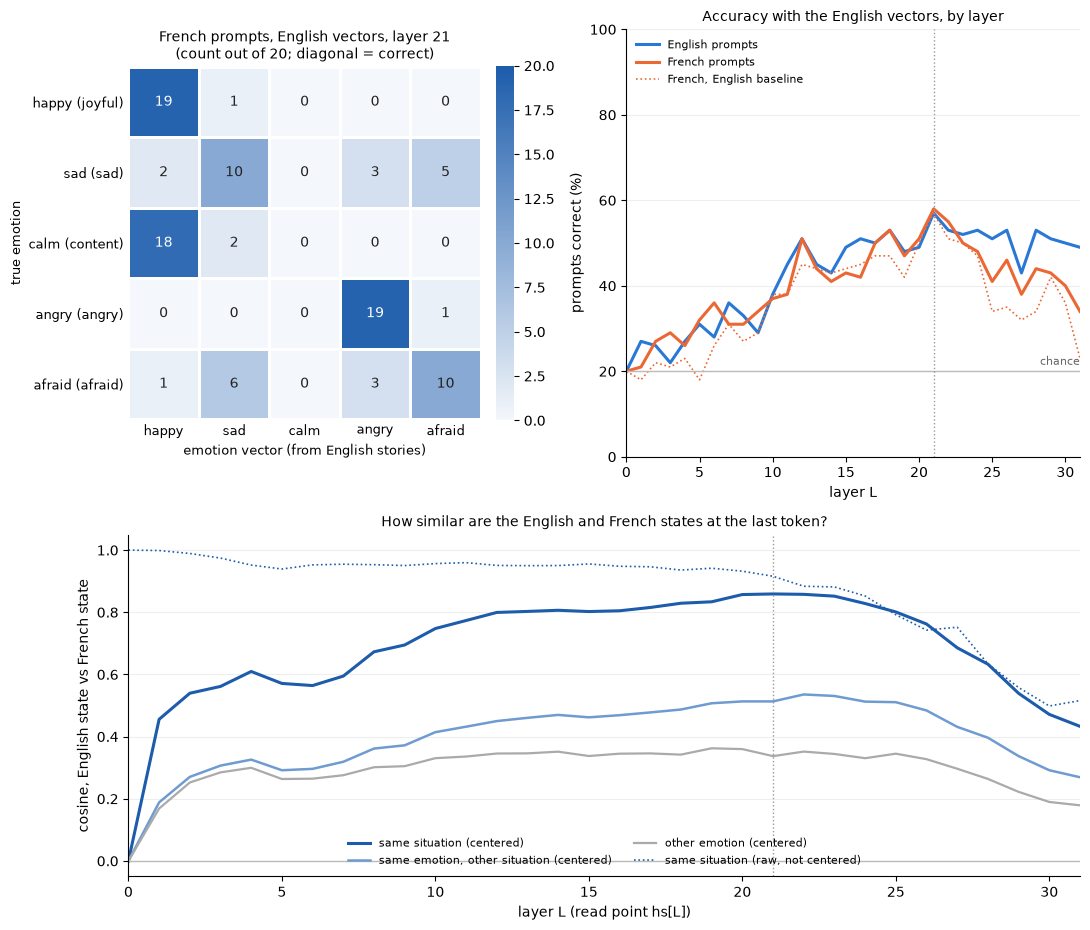

In [ ]:
fig, axd = plt.subplot_mosaic([["conf", "acc"], ["pairs", "pairs"]], figsize=(11, 9.4),
                              gridspec_kw={"height_ratios": [1, 0.8], "width_ratios": [0.85, 1]})
n = len(EMOTIONS)

ax = axd["conf"]                                                    # (a) French: the top vector for each prompt
im = ax.pcolormesh(conf_fr.numpy(), cmap=blues, vmin=0, vmax=N_PER, edgecolors="white", linewidth=2)   # blues from §8b
for i in range(n):
    for j in range(n):
        v = conf_fr[i, j].item()
        ax.text(j + 0.5, i + 0.5, v, ha="center", va="center", fontsize=10, color="white" if v > 0.6 * N_PER else "#222")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).outline.set_visible(False)
ax.set_title(f"French prompts, English vectors, layer {LAYER}\n(count out of {N_PER}; diagonal = correct)", fontsize=10)
ax.set_xticks(np.arange(n) + 0.5, EMOTIONS, fontsize=9)
ax.set_yticks(np.arange(n) + 0.5, [f"{e} ({ED_LABEL[e]})" for e in EMOTIONS], fontsize=9)
ax.set_xlabel("emotion vector (from English stories)", fontsize=9)
ax.set_ylabel("true emotion", fontsize=9)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

ax = axd["acc"]                                                     # (b) accuracy at each layer, both languages
ax.plot(range(32), [100 * a for a in acc_en], color="#2a78d6", linewidth=2.2, label="English prompts")
ax.plot(range(32), [100 * a for a in acc_fr], color="#eb6834", linewidth=2.2, label="French prompts")
ax.plot(range(32), [100 * a for a in acc_fr_en_center], color="#eb6834", linewidth=1.2, linestyle=":",
        label="French, English baseline")
ax.axhline(20, color="#bbb", linewidth=1)
ax.text(31, 21.5, "chance", fontsize=8, color="#666", ha="right")
ax.axvline(LAYER, color="#999", linewidth=1, linestyle=":")
ax.set_xlim(0, 31)
ax.set_ylim(0, 100)
ax.set_xlabel("layer L")
ax.set_ylabel("prompts correct (%)")
ax.set_title("Accuracy with the English vectors, by layer", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")

ax = axd["pairs"]                                                   # (c) English–French similarity of the internal state
styles = {"same situation": dict(color="#1c5cab", linewidth=2.2),
          "same emotion, other situation": dict(color="#6f9bd1", linewidth=1.8),
          "other emotion": dict(color="#aaa", linewidth=1.6)}
for k, st in styles.items():
    ax.plot(range(32), pair_sim[k], label=f"{k} (centered)", **st)
ax.plot(range(32), raw_same_situation, color="#1c5cab", linewidth=1.2, linestyle=":", label="same situation (raw, not centered)")
ax.axhline(0, color="#bbb", linewidth=1)
ax.axvline(LAYER, color="#999", linewidth=1, linestyle=":")
ax.set_xlim(0, 31)
ax.set_xlabel("layer L (read point hs[L])")
ax.set_ylabel("cosine, English state vs French state")
ax.set_title("How similar are the English and French states at the last token?", fontsize=10)
ax.set_ylim(-0.05, 1.05)
ax.legend(frameon=False, fontsize=8, loc="lower center", ncol=2)
for k in ["acc", "pairs"]:
    axd[k].grid(axis="y", color="#eee")
    for side in ["top", "right"]:
        axd[k].spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 10. More languages: Chinese, Arabic, Swahili

The same test as §9, with three more languages. Each one adds something that French does not:
- **Chinese:** a different writing system, almost no shared words, and Qwen knows it very well.
- **Arabic:** a different alphabet, written right to left.
- **Swahili:** the Latin alphabet, but different words, and much less training text. If the transfer fails here, the cause can be that Qwen understands Swahili less well, not that the vectors are English-only.

The prompts are the same 100 situations and 20 neutral prompts, translated by Claude with the same rules as French: `data/implicit_prompts_{zh,ar,sw}.jsonl`, each line paired with its English twin.

**Method and pass rule (fixed before the run):** the same as §9. English vectors, layer 21, last token, each language centered on its own neutral prompts. Transfer = 40 or more of 100 correct and the diagonal wins in at least 4 of 5 rows; no transfer = fewer than 30.

**Guess:** none (skipped).

In [ ]:
LANGS = {"en": "English", "fr": "French", "zh": "Chinese", "ar": "Arabic", "sw": "Swahili"}

def language_texts(code):
    """the 100 situations and the 20 neutral prompts in one language, in the same order as English"""
    if code == "en":
        return [t for _, t in implicit], NEUTRAL
    rows = [json.loads(line) for line in open(f"../data/implicit_prompts_{code}.jsonl")]
    assert [d["text_en"] for d in rows[:100]] == [t for _, t in implicit]
    return [d["text"] for d in rows[:100]], [d["text"] for d in rows[100:]]

def evaluate_language(code):
    """English vectors on one language; each language is centered on its own neutral prompts"""
    texts, neutral = language_texts(code)
    if code == "en":
        acts, neu = imp_acts, neu_acts                              # computed in §8b
    elif code == "fr":
        acts, neu = imp_fr, neu_fr                                  # computed in §9
    else:
        acts, neu = last_token_acts(texts), last_token_acts(neutral)
    center = neu.mean(0)
    S = emotion_scores(acts, LAYER, center)
    p = S.argmax(1)
    conf = torch.zeros(5, 5, dtype=torch.int)
    for t, q in zip(y.tolist(), p.tolist()):
        conf[t, q] += 1
    mc = torch.stack([S[y == i].mean(0) for i in range(5)]).numpy()
    return dict(
        acc=[accuracy(acts, center, L) for L in range(32)],
        sim=[F.cosine_similarity(imp_acts[:, L] - center_en[L], acts[:, L] - center[L], dim=-1).mean().item() for L in range(32)],
        pred=p, conf=conf, correct=(p == y).sum().item(), diag=int((mc.argmax(1) == np.arange(5)).sum()),
        tokens=np.mean([len(tokenizer(t, add_special_tokens=False).input_ids) for t in texts]))

def print_table(codes):
    print(f"layer {LAYER}, last token, English vectors, each language centered on its own neutral prompts\n")
    print(f"{'language':9} {'tokens':>6} {'correct':>8} {'sign':>5} {'same as EN':>10} {'cos EN':>7}  {'verdict':17} correct per emotion: " + " ".join(EMOTIONS))
    for code in codes:
        r = results[code]
        n = r["correct"]
        verdict = "(reference)" if code == "en" else "TRANSFER" if n >= 40 and r["diag"] >= 4 else "NO TRANSFER" if n < 30 else "PARTIAL TRANSFER"
        sign = (positive[r["pred"]] == positive[y]).sum().item()
        same = (r["pred"] == pred).sum().item()
        per = "  ".join(f"{r['conf'][i, i].item():>{len(e)}}" for i, e in enumerate(EMOTIONS))
        print(f"{LANGS[code]:9} {r['tokens']:6.1f} {n:>4}/100 {sign:>5} {same:>10} {r['sim'][LAYER]:7.2f}  {verdict:17}                      {per}")
    print("\ntokens = mean tokens for each prompt; sign = positive vs negative correct (of 100);"
          "\nsame as EN = same answer as the English twin (of 100); cos EN = cosine with the English state of the same situation")

results = {code: evaluate_language(code) for code in LANGS}
print_table(LANGS)

layer 21, last token, English vectors, each language centered on its own neutral prompts

language  tokens  correct  sign same as EN  cos EN  verdict           correct per emotion: happy sad calm angry afraid
English     21.7   57/100    92        100    1.00  (reference)                               18   13     0     20       6
French      27.9   58/100    94         80    0.86  TRANSFER                                  19   10     0     19      10
Chinese     17.2   56/100    92         81    0.86  TRANSFER                                  19   13     0     16       8
Arabic      26.4   58/100    92         83    0.80  TRANSFER                                  19   11     0     19       9
Swahili     36.8   46/100    82         64    0.50  PARTIAL TRANSFER                          17    5     0     15       9

tokens = mean tokens for each prompt; sign = positive vs negative correct (of 100);
same as EN = same answer as the English twin (of 100); cos EN = cosine with the English sta

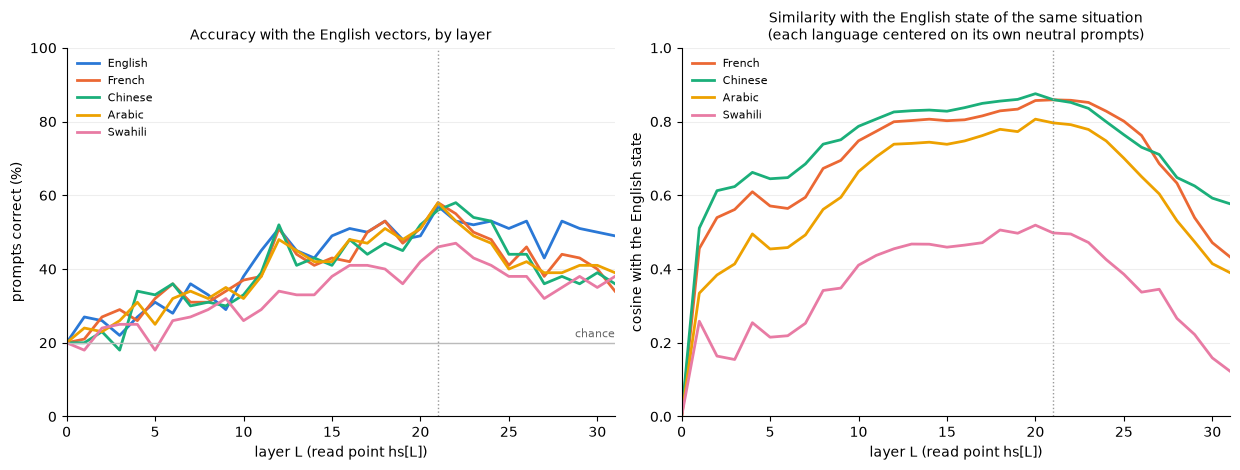

In [ ]:
COLORS = {"en": "#2a78d6", "fr": "#eb6834", "zh": "#1baf7a", "ar": "#eda100", "sw": "#e87ba4"}   # one fixed color per language
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
for code, r in results.items():
    ax1.plot(range(32), [100 * a for a in r["acc"]], color=COLORS[code], linewidth=2, label=LANGS[code])
    if code != "en":
        ax2.plot(range(32), r["sim"], color=COLORS[code], linewidth=2, label=LANGS[code])
ax1.axhline(20, color="#bbb", linewidth=1)
ax1.text(31, 21.5, "chance", fontsize=8, color="#666", ha="right")
ax1.set_ylim(0, 100)
ax1.set_ylabel("prompts correct (%)")
ax1.set_title("Accuracy with the English vectors, by layer", fontsize=10)
ax2.set_ylim(0, 1)
ax2.set_ylabel("cosine with the English state")
ax2.set_title("Similarity with the English state of the same situation\n(each language centered on its own neutral prompts)", fontsize=10)
for ax in (ax1, ax2):
    ax.axvline(LAYER, color="#999", linewidth=1, linestyle=":")
    ax.set_xlim(0, 31)
    ax.set_xlabel("layer L (read point hs[L])")
    ax.grid(axis="y", color="#eee")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 11. Three more European languages, and the recap

German, Italian and Spanish: the same 100 + 20 prompts, translated by Claude with the same rules (`data/implicit_prompts_{de,it,es}.jsonl`). The method and the pass rule are the same as §9 and §10, fixed before the run.

Then the recap: all eight languages in one table and one chart.

**Guess:** none (skipped).

In [ ]:
LANGS.update({"de": "German", "it": "Italian", "es": "Spanish"})
for code in ["de", "it", "es"]:
    results[code] = evaluate_language(code)

print_table(LANGS)          # the recap: all eight languages

layer 21, last token, English vectors, each language centered on its own neutral prompts

language  tokens  correct  sign same as EN  cos EN  verdict           correct per emotion: happy sad calm angry afraid
English     21.7   57/100    92        100    1.00  (reference)                               18   13     0     20       6
French      27.9   58/100    94         80    0.86  TRANSFER                                  19   10     0     19      10
Chinese     17.2   56/100    92         81    0.86  TRANSFER                                  19   13     0     16       8
Arabic      26.4   58/100    92         83    0.80  TRANSFER                                  19   11     0     19       9
Swahili     36.8   46/100    82         64    0.50  PARTIAL TRANSFER                          17    5     0     15       9
German      26.2   56/100    95         77    0.87  TRANSFER                                  19   15     0     13       9
Italian     26.3   55/100    91         78    0.86  T

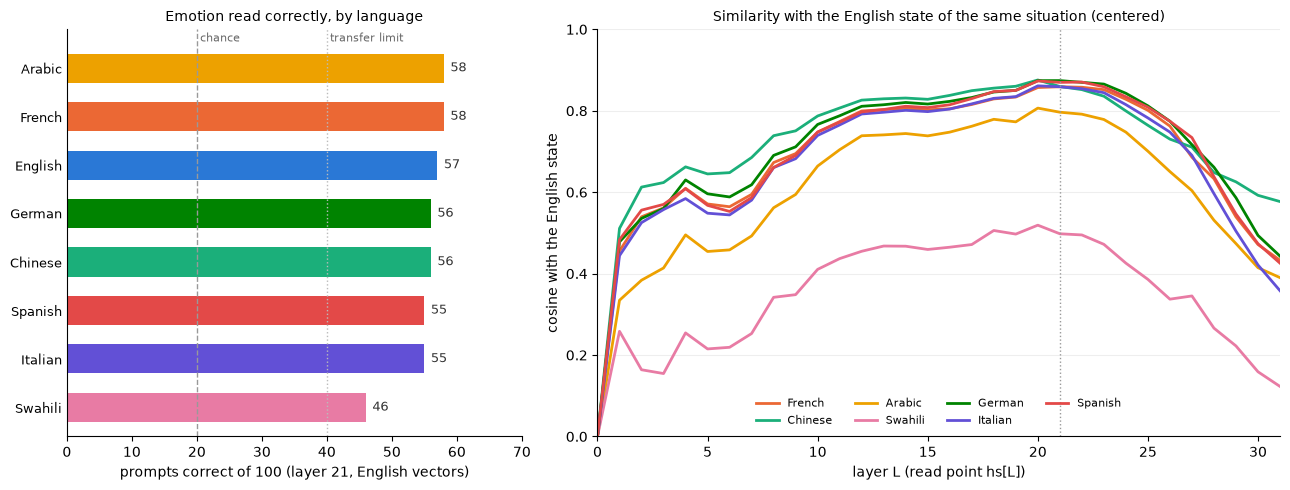

In [ ]:
COLORS.update({"de": "#008300", "it": "#6250d6", "es": "#e34948"})   # palette slots 6–8; the first five keep their colors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [0.8, 1.2]})

order = sorted(LANGS, key=lambda c: results[c]["correct"])                # (a) correct at layer 21, sorted
ax1.barh(range(len(order)), [results[c]["correct"] for c in order], height=0.6, color=[COLORS[c] for c in order])
for i, c in enumerate(order):
    ax1.text(results[c]["correct"] + 1, i, str(results[c]["correct"]), va="center", fontsize=9, color="#333")
ax1.set_yticks(range(len(order)), [LANGS[c] for c in order], fontsize=9)
ax1.axvline(20, color="#999", linewidth=1, linestyle="--")
ax1.text(20.5, len(order) - 0.45, "chance", fontsize=8, color="#666")
ax1.axvline(40, color="#bbb", linewidth=1, linestyle=":")
ax1.text(40.5, len(order) - 0.45, "transfer limit", fontsize=8, color="#666")
ax1.set_xlim(0, 70)
ax1.set_ylim(-0.6, len(order) - 0.2)
ax1.set_xlabel(f"prompts correct of 100 (layer {LAYER}, English vectors)")
ax1.set_title("Emotion read correctly, by language", fontsize=10)
ax1.tick_params(axis="y", length=0)

for code in LANGS:                                                        # (b) similarity with English, by layer
    if code != "en":
        ax2.plot(range(32), results[code]["sim"], color=COLORS[code], linewidth=2, label=LANGS[code])
ax2.axvline(LAYER, color="#999", linewidth=1, linestyle=":")
ax2.set_xlim(0, 31)
ax2.set_ylim(0, 1)
ax2.set_xlabel("layer L (read point hs[L])")
ax2.set_ylabel("cosine with the English state")
ax2.set_title("Similarity with the English state of the same situation (centered)", fontsize=10)
ax2.legend(frameon=False, fontsize=8, loc="lower center", ncol=4)
ax2.grid(axis="y", color="#eee")
for ax in (ax1, ax2):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()